# Question 1 — Regression from scratch
Linear · Multiple · Poly · Boost (better).  Change the lines marked `# <<<`.

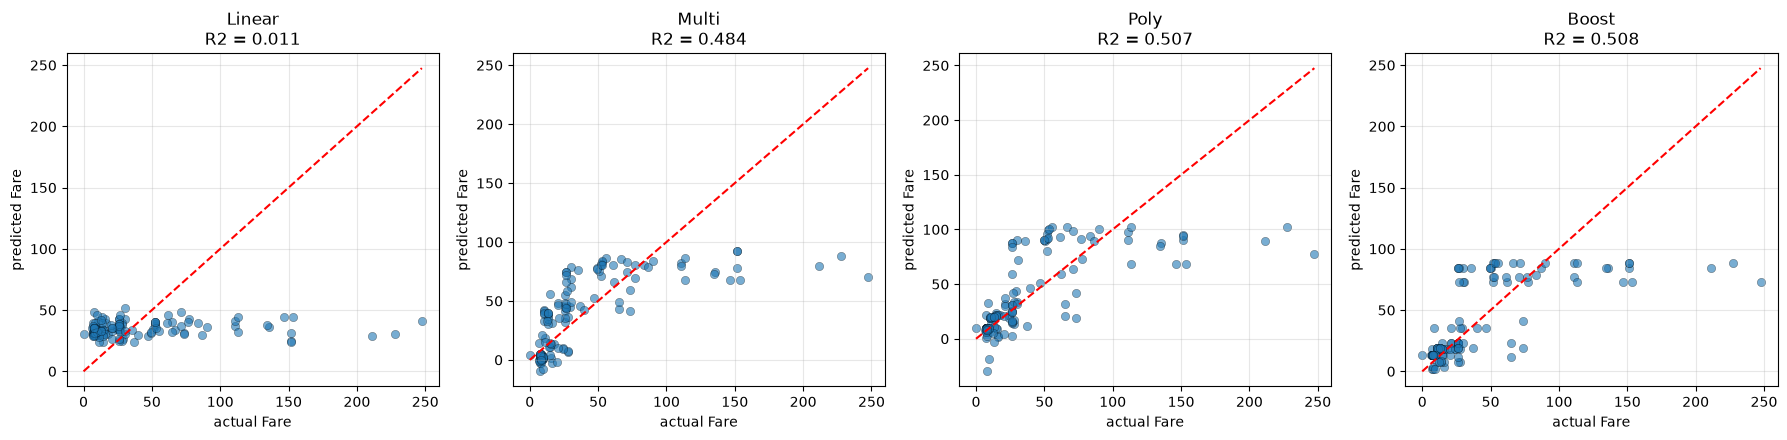

,model,R2
1,Boost,0.508366
2,Poly,0.507160
3,Multi,0.484337
4,Linear,0.011333


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../titanic.csv")          # <<<
cols = ["Age", "Pclass", "SibSp"]           # <<<
target = "Fare"                             # <<<

df = df[cols + [target]].dropna()
df = df.sample(frac=1, random_state=42)

x = df[cols].values
y = df[target].values

n = int(len(df)*0.8)
x_train, x_test, y_train, y_test = x[:n], x[n:], y[:n], y[n:]


def linear(x_train, y_train, x_test):
    x_train = np.column_stack([np.ones(len(x_train)), x_train])
    x_test = np.column_stack([np.ones(len(x_test)), x_test])
    w = np.linalg.pinv(x_train.T @ x_train) @ x_train.T @ y_train
    return x_test @ w


def boost(X_train, y_train, X_test):
    pred_train = np.full(len(y_train), y_train.mean())
    pred_test = np.full(len(X_test), y_train.mean())
    for _ in range(50):
        error = y_train - pred_train
        best = 1e18
        for j in range(X_train.shape[1]):
            for t in np.unique(X_train[:, j])[:-1]:
                left = X_train[:, j] <= t
                right = X_train[:, j] > t
                a, b = error[left].mean(), error[right].mean()
                fix_train = np.where(left, a, b)
                loss = ((error - fix_train) ** 2).sum()
                if loss < best:
                    best, best_train, best_test = loss, fix_train, np.where(X_test[:, j] <= t, a, b)
        pred_train += 0.1 * best_train
        pred_test += 0.1 * best_test
    return pred_test


def r2(y_test, y_pred):
    return 1 - (((y_test - y_pred) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum())


def show(pos, name, y_pred):
    plt.subplot(1, 4, pos)
    plt.scatter(y_test, y_pred, alpha=0.6, edgecolors="k", linewidths=0.3)
    plt.plot([0, y_test.max()], [0, y_test.max()], "r--")
    plt.title(f"{name}\nR2 = {r2(y_test, y_pred):.3f}")
    plt.xlabel("actual " + target)
    plt.ylabel("predicted " + target)
    plt.grid(alpha=0.3)


preds = {
    "Linear": linear(x_train[:, :1], y_train, x_test[:, :1]),
    "Multi": linear(x_train, y_train, x_test),
    "Poly": linear(np.column_stack([x_train, x_train**2]), y_train, np.column_stack([x_test, x_test**2])),
    "Boost": boost(x_train, y_train, x_test),
}

plt.figure(figsize=(18, 4.5))
for pos, (name, y_pred) in enumerate(preds.items(), 1):
    show(pos, name, y_pred)
plt.tight_layout()
plt.show()

rank = pd.DataFrame({"model": list(preds), "R2": [r2(y_test, p) for p in preds.values()]})
rank = rank.sort_values("R2", ascending=False).reset_index(drop=True)
rank.index += 1
rank